<a href="https://colab.research.google.com/github/julia-iza/Trabajo-Practico-Laboratorio/blob/main/SUBE_comparativo_graficos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SUBE frente a otros medios de pago

Gráficos comparativos y línea de tiempo con código Python.

Elaboración a partir del documento aportado. Los meses sin cifra SUBE publicada se dejan vacíos. Los datos tienen rezagos diferentes según el instrumento; no deben interpretarse como una serie perfectamente simultánea.

## Requisitos e importaciones

In [2]:
# -*- coding: utf-8 -*-
# Requisitos: matplotlib y numpy
import matplotlib.pyplot as plt
import numpy as np

## 1. Evolución de viajes SUBE vs. Viaje con QR

SUBE registra 270,21 millones de validaciones en julio de 2026; VQR llega a 26,33 millones en agosto de 2026 (+464,3% interanual).

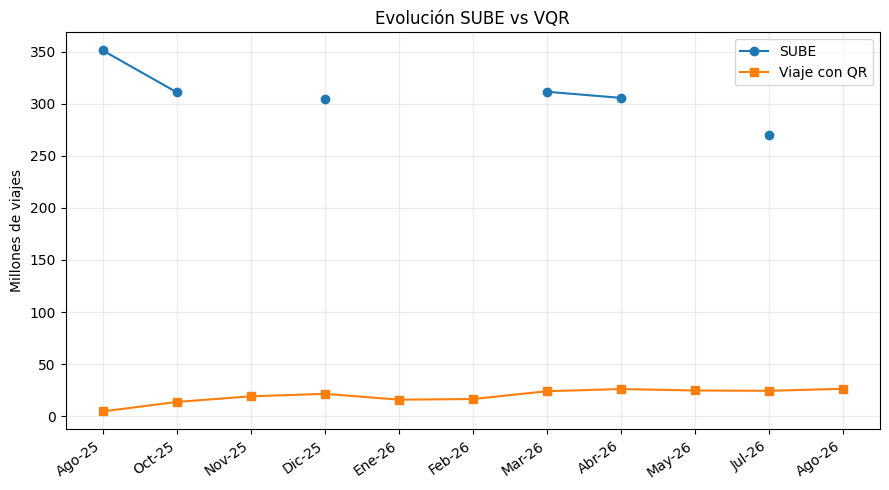

In [3]:
# GRAFICO 1: viajes SUBE vs Viaje con QR (millones)
meses = ["Ago-25","Oct-25","Nov-25","Dic-25","Ene-26","Feb-26",
         "Mar-26","Abr-26","May-26","Jul-26","Ago-26"]
sube = [351.2,311.0,None,305.0,None,None,311.5,305.6,None,270.21,None]
vqr = [4.6,13.7,19.1,21.5,15.9,16.5,24.0,26.1,24.7,24.4,26.33]
x = range(len(meses))
plt.figure(figsize=(9,5))
plt.plot(x,sube,marker="o",label="SUBE")
plt.plot(x,vqr,marker="s",label="Viaje con QR")
plt.xticks(list(x),meses,rotation=35,ha="right")
plt.ylabel("Millones de viajes"); plt.title("Evolución SUBE vs VQR")
plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.show()

## 2. Frecuencia de uso frente a volumen monetario

SUBE concentra 33,87% de operaciones pero 0,89% del monto. Crédito concentra 46% del monto y 19,97% de operaciones.

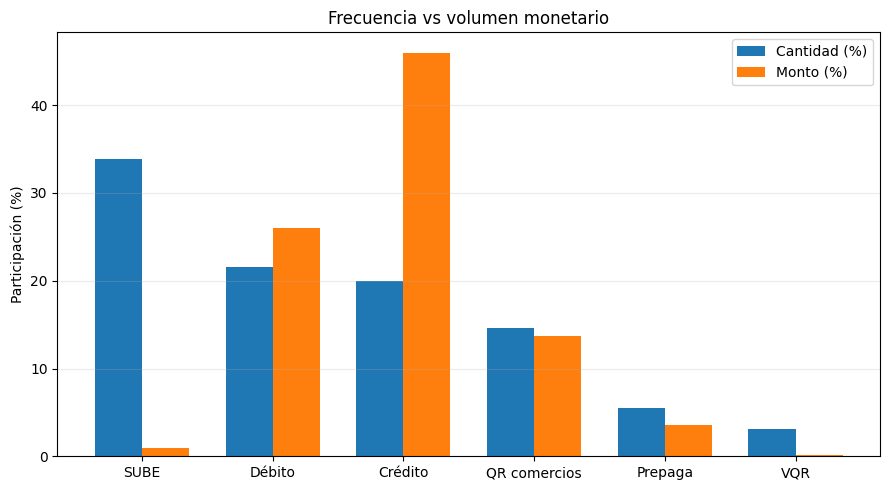

In [4]:
# GRAFICO 2: participacion en cantidad y monto (%)
medios=["SUBE","Débito","Crédito","QR comercios","Prepaga","VQR"]
cantidad=[33.87,21.56,19.97,14.65,5.45,3.06]
monto=[0.89,25.98,46.00,13.76,3.60,0.15]
pos=np.arange(len(medios)); w=.36
fig,ax=plt.subplots(figsize=(9,5))
ax.bar(pos-w/2,cantidad,w,label="Cantidad (%)")
ax.bar(pos+w/2,monto,w,label="Monto (%)")
ax.set_xticks(pos,medios); ax.set_ylabel("Participación (%)")
ax.set_title("Frecuencia vs volumen monetario")
ax.grid(axis="y",alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

## 3. Ticket promedio implícito

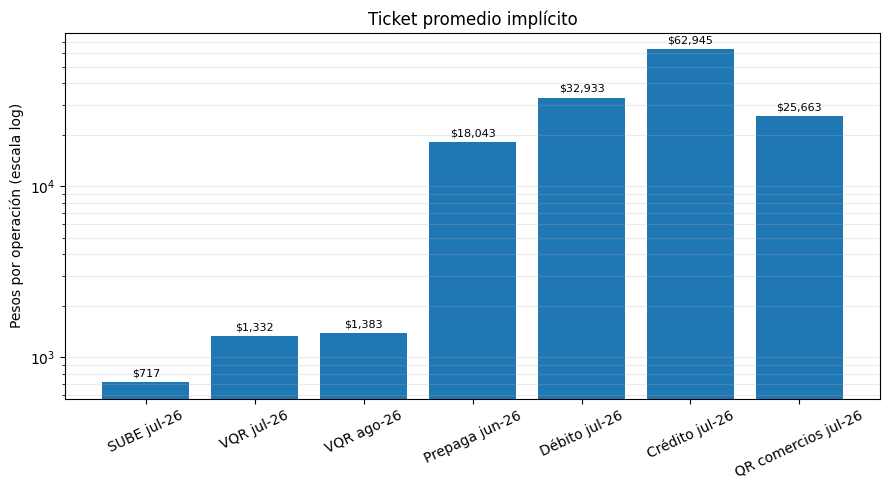

In [5]:
# GRAFICO 3: ticket promedio implicito (pesos, escala logaritmica)
nombres=["SUBE jul-26","VQR jul-26","VQR ago-26","Prepaga jun-26",
         "Débito jul-26","Crédito jul-26","QR comercios jul-26"]
tickets=[716.78,1331.97,1383.01,18042.78,32933.46,62944.84,25662.96]
fig,ax=plt.subplots(figsize=(9,5)); bars=ax.bar(nombres,tickets)
ax.set_yscale("log"); ax.set_ylabel("Pesos por operación (escala log)")
ax.set_title("Ticket promedio implícito")
ax.tick_params(axis="x",rotation=25); ax.grid(axis="y",which="both",alpha=.25)
for b,v in zip(bars,tickets):
    ax.text(b.get_x()+b.get_width()/2,v*1.08,f"${v:,.0f}",ha="center",fontsize=8)
plt.tight_layout(); plt.show()

## 4. Línea de tiempo de adopción

La cronología resume la apertura EMV/contactless, la incorporación del QR y la evolución de los volúmenes registrados.

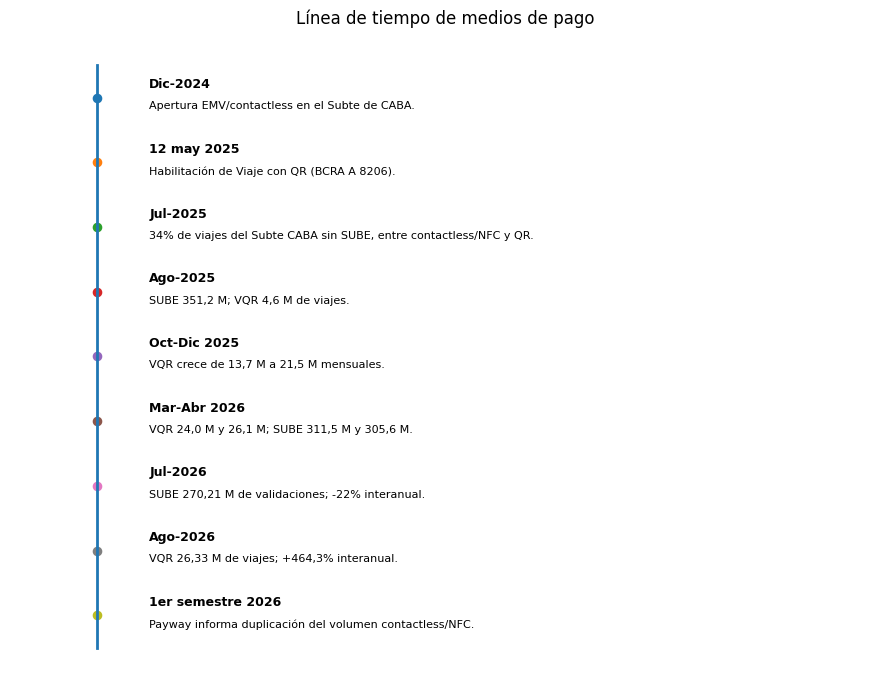

In [6]:
# LINEA DE TIEMPO: hitos documentados
eventos=[
("Dic-2024","Apertura EMV/contactless en el Subte de CABA."),
("12 may 2025","Habilitación de Viaje con QR (BCRA A 8206)."),
("Jul-2025","34% de viajes del Subte CABA sin SUBE, entre contactless/NFC y QR."),
("Ago-2025","SUBE 351,2 M; VQR 4,6 M de viajes."),
("Oct-Dic 2025","VQR crece de 13,7 M a 21,5 M mensuales."),
("Mar-Abr 2026","VQR 24,0 M y 26,1 M; SUBE 311,5 M y 305,6 M."),
("Jul-2026","SUBE 270,21 M de validaciones; -22% interanual."),
("Ago-2026","VQR 26,33 M de viajes; +464,3% interanual."),
("1er semestre 2026","Payway informa duplicación del volumen contactless/NFC.")
]
fig,ax=plt.subplots(figsize=(9,7)); ax.set_xlim(0,1); ax.set_ylim(0,len(eventos)+1); ax.axis("off")
ax.plot([.1,.1],[.5,len(eventos)+.5],lw=2)
for i,(fecha,detalle) in enumerate(eventos):
    y=len(eventos)-i
    ax.scatter([.1],[y],s=35)
    ax.text(.16,y+.1,fecha,fontsize=9,fontweight="bold",va="bottom")
    ax.text(.16,y-.06,detalle,fontsize=8,va="top")
ax.set_title("Línea de tiempo de medios de pago")
plt.tight_layout(); plt.show()